---
title: "Free Energy, Chemical Potential and Phase Equilibria — Level 2"
short_title: "05 Free Energy & Phases"
numbering:
  heading_2: true
  equation: true
---

# Free Energy, Chemical Potential and Phase Equilibria

:::{seealso} Math for this topic
- [T-M3: Exact differentials and thermodynamic calculus](../math/03-thermodynamic-calculus.ipynb)
- [M1: Vectors and ODEs](../../level2-book/math/01-vectors-odes.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (a gap in Tipler & Mosca) | Not covered; start at Level 2 |
| **2** | **Schroeder, ch. 5** | **Helmholtz and Gibbs free energy, Clausius–Clapeyron, chemical equilibrium** |
| 3 | Pathria, ch. 3–4 | Grand canonical ensemble, fugacity, phase coexistence |

The new skill at this level: replacing 'maximize the entropy of the universe' with 'minimize the free energy of the system', which only needs the system's own properties

Math for this topic: T-M3 (Legendre transforms, Maxwell relations, Lagrange multipliers) and mechanics M1 (first-order ODEs).
:::

Workbook example ladder: latent heat of fusion → the slope of a coexistence curve from Clausius–Clapeyron → grand partition function of a lattice gas. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Free Energy as Available Work

To create a system out of nothing in an environment at temperature $T$, you must supply its energy $U$, but the environment can donate heat $TS$ for free (that heat carries in exactly the entropy the system needs). The work you must actually supply is the **Helmholtz free energy**:

$$
F = U - TS .
$$ (eq-helmholtz)

If the environment is also at pressure $P$, you must additionally pay $PV$ to push the atmosphere aside and make room, giving the **Gibbs free energy**:

$$
G = U - TS + PV = H - TS .
$$ (eq-gibbs)

Run the argument backward: in a process at constant $T$ (and $P$), the maximum work you can extract other than expansion work is $-\Delta F$ (or $-\Delta G$). A battery's voltage, for example, is $-\Delta G$ per unit charge of its chemical reaction.

Their differentials follow from the thermodynamic identity $dU = T\,dS - P\,dV + \mu\,dN$ (T-M3 has the Legendre-transform bookkeeping):

$$
dF = -S\,dT - P\,dV + \mu\,dN ,\qquad dG = -S\,dT + V\,dP + \mu\,dN .
$$ (eq-dF-dG)

## Free Energy as a Force Toward Equilibrium

:::{prf:theorem} Minimum free energy
:label: thm-min-free-energy

A system in contact with a reservoir at temperature $T$ (fixed $V$, $N$) evolves to decrease $F$; at fixed $T$ and $P$ it evolves to decrease $G$. Equilibrium is the minimum.
:::

:::{prf:proof}
:class: dropdown

The total entropy of system plus reservoir must increase. Energy $dU$ entering the system leaves the reservoir, whose entropy changes by $-dU/T$. So

$$
dS_{\text{total}} = dS - \frac{dU}{T} = -\frac{1}{T}\left(dU - T\,dS\right) = -\frac{dF}{T}\ge0 .
$$

At constant $P$ the reservoir also gives up volume, adding $-P\,dV/T$, and the same steps give $dS_{\text{total}} = -dG/T$.
:::

This is why free energy matters: **maximizing the total entropy of the universe is the same as minimizing the system's free energy**, and the second needs only the system's own $U$, $S$, $V$.

The minimum is a competition. Low $U$ favors order (atoms bound in a crystal); high $S$ favors disorder (a gas). At low $T$ the energy term wins, at high $T$ the entropy term wins, and a phase transition happens where they balance.

## Chemical Potential

$\mu$ is the free-energy cost of adding one particle at fixed $T$ and $P$. Since $G$ is extensive and $T$, $P$ are not, $G$ must be proportional to $N$ for a single substance, so

$$
G = N\mu .
$$ (eq-G-equals-N-mu)

Particles flow from high $\mu$ to low $\mu$, just as energy flows from high $T$ to low $T$. For an ideal gas, $\mu = \mu^\circ(T) + kT\ln(P/P^\circ)$: at fixed temperature, compressing a gas raises its chemical potential logarithmically.

## Phase Transformations

Two phases (say liquid and vapor) coexist in equilibrium when moving a molecule between them costs nothing: $\mu_{\text{liquid}}(T, P) = \mu_{\text{vapor}}(T, P)$. In the $PT$ plane this one equation defines a curve, the **coexistence curve** (phase boundary).

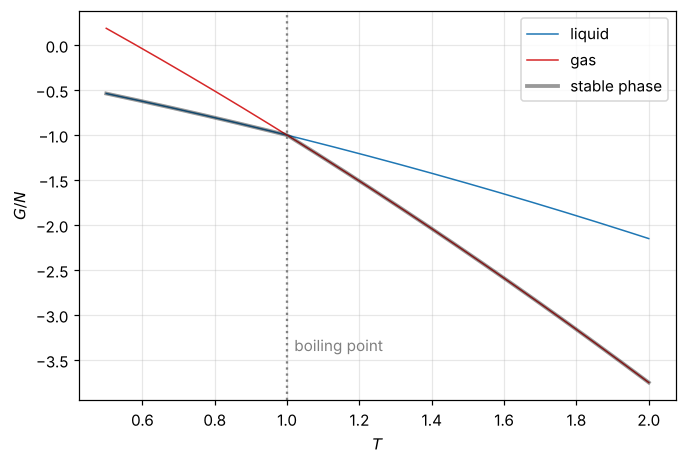

In [2]:
#| label: fig-g-crossing
#| caption: "Gibbs free energy per molecule of two phases versus temperature at fixed pressure (schematic, arbitrary units). The slope is −S (from dG = −S dT + V dP), and the gas, with more entropy, is steeper. The stable phase is whichever is lower; the crossing is the boiling point, and the change of slope there is the entropy jump L/T."
T = np.linspace(0.5, 2.0, 200)
g_liq = -1.0 - 1.0 * (T - 1.0) - 0.15 * (T - 1.0)**2
g_gas = -1.0 - 2.5 * (T - 1.0) - 0.25 * (T - 1.0)**2
fig, ax = plt.subplots()
ax.plot(T, g_liq, color="tab:blue", label="liquid", lw=1); ax.plot(T, g_gas, color="tab:red", label="gas", lw=1)
ax.plot(T, np.minimum(g_liq, g_gas), color="k", lw=2.5, alpha=0.4, label="stable phase")
ax.axvline(1.0, ls=":", color="gray"); ax.text(1.02, -3.4, "boiling point", color="gray")
ax.set_xlabel("$T$"); ax.set_ylabel("$G/N$"); ax.legend(); plt.show()

:::{prf:theorem} Clausius–Clapeyron relation
:label: thm-clausius-clapeyron

The slope of a coexistence curve is

$$
\frac{dP}{dT} = \frac{L}{T\,\Delta V} ,
$$ (eq-clausius-clapeyron)

where $L$ is the latent heat and $\Delta V$ the volume change of the transformation (same amount of substance for both).
:::

:::{prf:proof}
:class: dropdown

Move along the curve by $(dT, dP)$. The two phases' Gibbs energies stay equal, so their changes are equal: $-S_1dT + V_1dP = -S_2dT + V_2dP$. Then $dP/dT = (S_2 - S_1)/(V_2 - V_1) = \Delta S/\Delta V$, and $\Delta S = L/T$ because the latent heat enters at fixed $T$.
:::

::::{prf:example} Level 1 rung: why ice skates glide (partly)
:label: ex-ice-slope

Ice melting at 0 °C has $L = 6.01$ kJ/mol, and the molar volume *drops* from 19.65 cm³ (ice) to 18.02 cm³ (water). Find the slope of the melting curve.

:::{dropdown} Solution
$\Delta V = -1.63\times10^{-6}$ m³/mol, so

$$
\frac{dP}{dT} = \frac{6010}{273.15\times(-1.63\times10^{-6})} = -1.35\times10^7\ \text{Pa/K} = -134\ \text{atm/K} .
$$

The slope is negative because ice is less dense than water: pressure favors the denser phase, so squeezing ice lowers its melting point. But 134 atm per kelvin is a lot. A skater's blade lowers the melting point by only a degree or two, so pressure melting alone cannot explain skating at −10 °C; friction heating and a thin premelted surface layer do most of the work.
:::
::::

### The vapor-pressure curve

For liquid–vapor coexistence far from the critical point, the vapor's volume dwarfs the liquid's, so $\Delta V\approx V_{\text{gas}} = RT/P$ per mole. Then {eq}`eq-clausius-clapeyron` is a first-order separable ODE:

$$
\frac{dP}{dT} = \frac{LP}{RT^2}\quad\Rightarrow\quad P(T) = P_0\exp\!\left[-\frac LR\left(\frac1T - \frac1{T_0}\right)\right] .
$$ (eq-vapor-pressure)

In [3]:
Ps, Ts_, L_, R_ = sp.symbols("P T L R", positive=True)
Pf = sp.Function("P")
sol = sp.dsolve(sp.Eq(Pf(Ts_).diff(Ts_), L_ * Pf(Ts_) / (R_ * Ts_**2)))
display(Math(sp.latex(sol)))

<IPython.core.display.Math object>

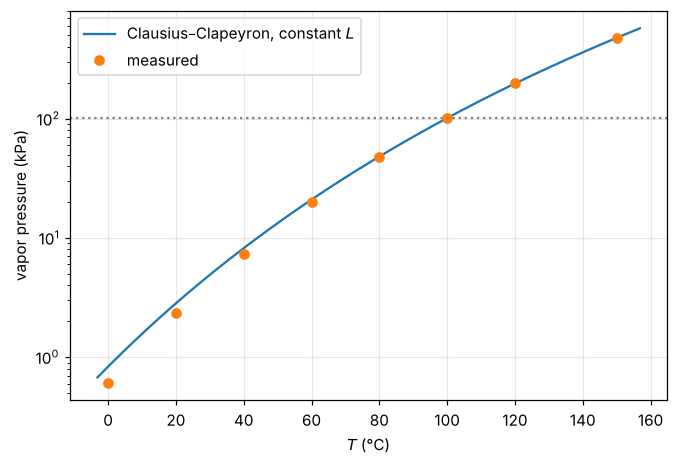

In [4]:
#| label: fig-vapor-pressure
#| caption: "Vapor pressure of water. The curve integrates Clausius–Clapeyron from the normal boiling point (373.15 K, 1 atm) with a constant L = 40.7 kJ/mol; dots are measured values. Agreement is within about 10% from 40 °C to 150 °C but drifts to 36% high at 0 °C, because L is really larger at low temperature (about 45 kJ/mol at 0 °C)."
T_data = np.array([273.16, 293.15, 313.15, 333.15, 353.15, 373.15, 393.15, 423.15])
P_data = np.array([0.6117, 2.339, 7.385, 19.95, 47.41, 101.42, 198.7, 476.2])  # kPa
L = 40.7e3; T0, P0 = 373.15, 101.325
TT = np.linspace(270, 430, 300)
fig, ax = plt.subplots()
ax.semilogy(TT - 273.15, P0 * np.exp(-L / R_gas * (1 / TT - 1 / T0)), label="Clausius–Clapeyron, constant $L$")
ax.semilogy(T_data - 273.15, P_data, "o", label="measured")
ax.axhline(101.325, ls=":", color="gray")
ax.set_xlabel("$T$ (°C)"); ax.set_ylabel("vapor pressure (kPa)"); ax.legend(); plt.show()

::::{prf:example} Level 2 rung: boiling on a mountain
:label: ex-boiling-altitude

At the summit of Denali the air pressure is about 46 kPa. At what temperature does water boil?

:::{dropdown} Solution
Solve {eq}`eq-vapor-pressure` for $T$:

$$
\frac1T = \frac1{T_0} - \frac RL\ln\frac{P}{P_0} = \frac{1}{373.15} - \frac{8.314}{40700}\ln\frac{46}{101.3} = 2.841\times10^{-3}\ \text{K}^{-1},
$$

so $T = 352$ K, or about 79 °C. Pasta takes noticeably longer to cook up there.
:::
::::

## Chemical Equilibrium

For a reaction such as $\mathrm{N_2 + 3H_2\rightleftharpoons 2NH_3}$, the minimum of $G$ at fixed $T$ and $P$ requires the stoichiometric combination of chemical potentials to vanish: $2\mu_{\mathrm{NH_3}} - \mu_{\mathrm{N_2}} - 3\mu_{\mathrm{H_2}} = 0$. With the ideal-gas form of $\mu$, this becomes the **law of mass action**:

$$
\frac{(P_{\mathrm{NH_3}}/P^\circ)^2}{(P_{\mathrm{N_2}}/P^\circ)(P_{\mathrm{H_2}}/P^\circ)^3} = K = e^{-\Delta G^\circ/RT} ,
$$ (eq-mass-action)

where $\Delta G^\circ$ is the reaction's Gibbs energy change with everything at the reference pressure $P^\circ$. A negative $\Delta G^\circ$ means $K > 1$ (products favored); the temperature dependence of $K$ comes from $\Delta G^\circ = \Delta H^\circ - T\Delta S^\circ$.

## Looking Ahead to Level 3

Pathria handles particle exchange with the **grand canonical ensemble**: a system that trades both energy and particles with a reservoir at $(T, \mu)$. Its normalizing sum is the grand partition function $\mathcal Z = \sum e^{-(E - \mu N)/kT}$, and the variable $z = e^{\mu/kT}$, the **fugacity**, controls the number of particles. For a lattice gas (sites that are each empty or filled), $\mathcal Z$ factors site by site, and the occupancy comes out as $1/(e^{(\epsilon - \mu)/kT} + 1)$, a Fermi–Dirac form you will meet again in thermo topic 7.

## Exercises

### Exercises

1. Show from {eq}`eq-dF-dG` that $S = -(\partial F/\partial T)_V$ and $P = -(\partial F/\partial V)_T$.
2. A hydrogen fuel cell runs $\mathrm{H_2 + \tfrac12O_2\to H_2O(l)}$ with $\Delta H = -286$ kJ and $\Delta G = -237$ kJ per mole at 298 K. Find the maximum electrical work, the heat expelled, and the voltage (two electrons per H₂).
3. Use Clausius–Clapeyron to estimate the vapor pressure of water at 50 °C, and compare with the measured 12.35 kPa.
4. Graphite and diamond: $\Delta G^\circ = +2.9$ kJ/mol (diamond higher) at 298 K and 1 bar, and diamond is denser (3.42 vs 2.01 cm³/mol difference: $V_{\text{graphite}} - V_{\text{diamond}} = 1.89$ cm³/mol). Estimate the pressure above which diamond is stable at room temperature, treating volumes as constant.
5. Why is $\mu$ for a gas lowered by dilution? What does this imply for a drop of perfume in a room?

:::{dropdown} Hints
1. Read off the coefficients of $dT$ and $dV$.
2. $W_{\max} = -\Delta G$; heat expelled $= -\Delta H - W$; $V = W/(2e)$ per molecule, or $W/(2F)$ per mole ($F = 96\,485$ C/mol).
3. Use {eq}`eq-vapor-pressure` with $T = 323.15$ K.
4. $(\partial G/\partial P)_T = V$, so $\Delta G$ changes at rate $\Delta V$ with pressure.
5. $\mu = \mu^\circ + kT\ln(P/P^\circ)$ as $P\to0$.
:::

:::{dropdown} Answers
1. $dF = -S\,dT - P\,dV$, so the partial derivatives are the coefficients.
2. $W = 237$ kJ; heat out $= 49$ kJ (that is $T\Delta S$); voltage $= 237\,000/(2\times96\,485) = 1.23$ V.
3. $P = 101.3\exp[-4895(1/323.15 - 1/373.15)] = 13.3$ kPa, about 8% high.
4. $\Delta G$ falls by $1.89\times10^{-6}$ m³/mol per Pa: $P\approx 2900/1.89\times10^{-6} = 1.5\times10^9$ Pa, about 15 000 bar. (Diamond at the surface is metastable: the conversion is incredibly slow.)
5. $\mu\to-\infty$ logarithmically as the partial pressure goes to zero, so molecules always lower $G$ by spreading out; the perfume fills the room.
:::

## Summary

- $F = U - TS$ and $G = U - TS + PV$ are the work needed to create a system with help from the environment; $-\Delta F$, $-\Delta G$ bound the useful work out.
- At fixed $T$ (and $P$), systems minimize $F$ (or $G$): the same as maximizing total entropy, but needing only system quantities.
- $\mu$ is the Gibbs energy per particle; particles flow toward lower $\mu$, and phases coexist where $\mu$'s are equal.
- Clausius–Clapeyron $dP/dT = L/T\Delta V$ gives phase-boundary slopes and, for vapor, the exponential vapor-pressure curve.
- Chemical equilibrium: $K = e^{-\Delta G^\circ/RT}$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.